# DSCI 552 - Homework 7

**Karan Timmala** | GitHub: karantimmala | USC ID: 1373267232

In [1]:
from pathlib import Path
import os
import pandas as pd
import numpy as np
from IPython.display import display
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.svm import SVC, LinearSVC
from sklearn.multiclass import OneVsRestClassifier
from sklearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as SamplingPipeline
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, pairwise_distances
from joblib import Parallel, delayed, parallel_config
from threadpoolctl import threadpool_limits
import matplotlib.pyplot as plt

## 1. Multi-class, multi-output SVM classification

### 1(a) Data and 70/30 random split
Use the 22 MFCC predictors; exclude RecordID and keep Family, Genus, and Species as outputs.

In [2]:
# Look beside the notebook first, then in common data folders.
data_folders = [Path('.'), Path('../data'), Path('data'), Path('upload'),
                Path('../upload'), Path('../data/Anuran Calls (MFCCs)')]
data_names = ['Frogs_MFCCs.csv', 'Frogs_MFCCs(1).csv']
data_path = next((folder / name for folder in data_folders
                  for name in data_names if (folder / name).is_file()), None)
if data_path is None:
    raise FileNotFoundError('Place Frogs_MFCCs.csv beside this notebook or in ../data/.')
df = pd.read_csv(data_path)
X = df.drop(columns=['Family', 'Genus', 'Species', 'RecordID'])
y = df[['Family', 'Genus', 'Species']]
# Keep the original random 70/30 split for the supervised comparisons.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, train_size=0.7, random_state=42, shuffle=True
)
print('X_train:', X_train.shape)
print('X_test:', X_test.shape)
print('y_train:', y_train.shape)
print('y_test:', y_test.shape)

X_train: (5036, 22)
X_test: (2159, 22)
y_train: (5036, 3)
y_test: (2159, 3)


### 1(b)(i) Evaluation
Train one multiclass classifier per output (binary relevance). Evaluate both whole-triplet and individual-output predictions.

In multilabel classification, each instance may be associated with more than one label at the same time, so evaluation metrics must consider performance across all labels rather than a single output.

**Exact Match (Subset Accuracy)** is a strict metric that counts a prediction as correct only when the entire set of predicted labels exactly matches the true labels for an instance. If even one label is predicted incorrectly, the whole prediction is considered wrong. Because of this strict requirement, exact match is a demanding metric and typically produces lower scores, especially when the number of labels is large.

**Hamming Loss** measures the fraction of labels that are incorrectly predicted, including both false positives and false negatives, averaged over all labels and instances. Since it evaluates errors at the label level, it is more forgiving than exact match. A smaller Hamming loss indicates better model performance.

**Average Hamming distance:** mean number of mismatches per observation (0-3).

**Hamming Score (Label-based Accuracy)** is defined as one minus the Hamming loss and represents the proportion of correctly predicted labels. Unlike exact match, it assesses accuracy for each label independently rather than requiring all labels to be correct at once, making it a more flexible and informative metric for multilabel classification.

Higher exact match/score and lower distance/loss are better.

In [3]:
# Label Encoding
encoders = {}
y_train_enc = pd.DataFrame()
y_test_enc = pd.DataFrame()
for label in y_train.columns:
    lEnc = LabelEncoder()
    y_train_enc[label] = lEnc.fit_transform(y_train[label])
    y_test_enc[label] = lEnc.transform(y_test[label])
    encoders[label] = lEnc
# Evaluation Function
def evaluate(y_true, y_pred, name):
    y_true = y_true.values
    y_pred = y_pred.values
    # Exact Match
    exact = np.mean(np.all(y_true == y_pred, axis=1))
    # Hamming Loss
    h_loss = np.mean(y_true != y_pred)
    # Hamming Score
    h_score = 1 - h_loss
    print(f"\n{name}")
    print("Exact Match:", exact)
    print("Hamming Loss:", h_loss)
    print("Hamming Score:", h_score)

In [4]:
evaluate(y_test_enc, y_test_enc, "Sanity Check")


Sanity Check
Exact Match: 1.0
Hamming Loss: 0.0
Hamming Score: 1.0


### 1(b)(ii) Gaussian SVM
Fit one-versus-rest RBF classifiers on raw and standardized predictors. Select C and gamma with 10-fold CV; report sigma = sqrt(1 / (2 x gamma)).

In [5]:
# parameter grid for RBF SVM
c_values = [0.1, 1, 10, 100]
gamma_values = [0.001, 0.01, 0.1, 1]
param_grid_raw = { "estimator__C": c_values, "estimator__gamma": gamma_values }
param_grid_scaled = { "ovr__estimator__C": c_values, "ovr__estimator__gamma": gamma_values }
# store models and predictions
raw_models = {}
scaled_models = {}
raw_preds = {}
scaled_preds = {}
# RAW FEATURES
for label in y_train_enc.columns:
    print(f"\nTraining RBF SVM on RAW features for {label}")

    raw_ovr = OneVsRestClassifier(SVC(kernel="rbf"))

    raw_grid = GridSearchCV(
        estimator=raw_ovr,
        param_grid=param_grid_raw,
        cv=10,
        scoring="accuracy",
        n_jobs=-1
    )
    raw_grid.fit(X_train, y_train_enc[label])
    print("Best parameters:", raw_grid.best_params_)
    raw_models[label] = raw_grid
    raw_preds[label] = raw_grid.predict(X_test)
# convert predictions to dataframe
y_pred_raw = pd.DataFrame(raw_preds)
y_pred_raw = y_pred_raw[y_train_enc.columns]
# evaluate raw model
evaluate(y_test_enc, y_pred_raw, "GAUSSIAN SVM - RAW FEATURES")
# STANDARDIZED FEATURES
for label in y_train_enc.columns:
    print(f"\nTraining RBF SVM on SCALED features for {label}")
    scaled_pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("ovr", OneVsRestClassifier(SVC(kernel="rbf")))
    ])
    scaled_grid = GridSearchCV(
        estimator=scaled_pipeline,
        param_grid=param_grid_scaled,
        cv=10,
        scoring="accuracy",
        n_jobs=-1
    )
    scaled_grid.fit(X_train, y_train_enc[label])
    print("Best parameters:", scaled_grid.best_params_)
    scaled_models[label] = scaled_grid
    scaled_preds[label] = scaled_grid.predict(X_test)
# convert predictions to dataframe
y_pred_scaled = pd.DataFrame(scaled_preds)
y_pred_scaled = y_pred_scaled[y_train_enc.columns]
# evaluate scaled model
evaluate(y_test_enc, y_pred_scaled, "GAUSSIAN SVM - SCALED FEATURES")
# Report the Gaussian width explicitly: gamma = 1 / (2 * sigma**2).
kernel_rows = []
for feature_set, searches, prefix in [
    ('Raw', raw_models, 'estimator__'),
    ('Standardized', scaled_models, 'ovr__estimator__')
]:
    for label, search in searches.items():
        best_gamma = search.best_params_[prefix + 'gamma']
        kernel_rows.append({
            'Features': feature_set,
            'Label': label,
            'Best C': search.best_params_[prefix + 'C'],
            'Best gamma': best_gamma,
            'Gaussian width (sigma)': np.sqrt(1 / (2 * best_gamma)),
            'Best 10-fold CV accuracy': search.best_score_
        })
kernel_table = pd.DataFrame(kernel_rows)
display(kernel_table)


Training RBF SVM on RAW features for Family
Best parameters: {'estimator__C': 100, 'estimator__gamma': 1}

Training RBF SVM on RAW features for Genus
Best parameters: {'estimator__C': 10, 'estimator__gamma': 1}

Training RBF SVM on RAW features for Species
Best parameters: {'estimator__C': 10, 'estimator__gamma': 1}

GAUSSIAN SVM - RAW FEATURES
Exact Match: 0.9874942102825383
Hamming Loss: 0.0077196232823838196
Hamming Score: 0.9922803767176162

Training RBF SVM on SCALED features for Family
Best parameters: {'ovr__estimator__C': 10, 'ovr__estimator__gamma': 0.1}

Training RBF SVM on SCALED features for Genus
Best parameters: {'ovr__estimator__C': 10, 'ovr__estimator__gamma': 0.1}

Training RBF SVM on SCALED features for Species
Best parameters: {'ovr__estimator__C': 10, 'ovr__estimator__gamma': 0.1}

GAUSSIAN SVM - SCALED FEATURES
Exact Match: 0.9865678554886521
Hamming Loss: 0.010035510267098965
Hamming Score: 0.9899644897329011


,Features,Label,Best C,Best gamma,Gaussian width (sigma),Best 10-fold CV accuracy
0,Raw,Family,100,1.0,0.707107,0.992058
1,Raw,Genus,10,1.0,0.707107,0.990070
2,Raw,Species,10,1.0,0.707107,0.989871
3,Standardized,Family,10,0.1,2.236068,0.991462
4,Standardized,Genus,10,0.1,2.236068,0.989872
5,Standardized,Species,10,0.1,2.236068,0.988482


### 1(b)(iii) L1-penalized linear SVM
Standardize inside the pipeline and select C with 10-fold CV.

In [6]:
# parameter grid for L1 SVM
c_values_l1 = [0.01, 0.1, 1, 10, 100]
param_grid_l1 = { "svm__C": c_values_l1 }
# store models and predictions
l1_models = {}
l1_preds = {}
# STANDARDIZED FEATURES ONLY
for label in y_train_enc.columns:
    print(f"\nTraining L1 SVM on SCALED features for {label}")
    l1_pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("svm", LinearSVC(
            penalty="l1",
            dual=False,
            max_iter=20000,
            random_state=42
        ))
    ])
    l1_grid = GridSearchCV(
        estimator=l1_pipeline,
        param_grid=param_grid_l1,
        cv=10,
        scoring="accuracy",
        n_jobs=-1
    )
    l1_grid.fit(X_train, y_train_enc[label])
    print("Best parameters:", l1_grid.best_params_)
    l1_models[label] = l1_grid
    l1_preds[label] = l1_grid.predict(X_test)
# convert predictions to dataframe
y_pred_l1 = pd.DataFrame(l1_preds)
y_pred_l1 = y_pred_l1[y_train_enc.columns]
# evaluate L1 model
evaluate(y_test_enc, y_pred_l1, "L1 SVM - SCALED FEATURES (STANDARDIZED)")


Training L1 SVM on SCALED features for Family
Best parameters: {'svm__C': 1}

Training L1 SVM on SCALED features for Genus
Best parameters: {'svm__C': 10}

Training L1 SVM on SCALED features for Species
Best parameters: {'svm__C': 10}

L1 SVM - SCALED FEATURES (STANDARDIZED)
Exact Match: 0.9129226493747105
Hamming Loss: 0.05681642735834491
Hamming Score: 0.9431835726416551


### 1(b)(iv) L1 SVM with SMOTE
Apply scaling and SMOTE inside each CV training fold; leave the test set unchanged.

In [7]:
# parameter grid
c_values_smote = [0.01, 0.1, 1, 10, 100]
param_grid_smote = { "svm__C": c_values_smote }
# store models and predictions
smote_models = {}
smote_preds = {}
for label in y_train_enc.columns:
    print(f"\nTraining L1 SVM with SMOTE for {label}")
    smote_pipeline = SamplingPipeline([
        ("scaler", StandardScaler()),
        ("smote", SMOTE(random_state=42)),
        ("svm", LinearSVC(
            penalty="l1",
            dual=False,
            max_iter=20000,
            random_state=42
        ))
    ])
    smote_grid = GridSearchCV(
        estimator=smote_pipeline,
        param_grid=param_grid_smote,
        cv=10,
        scoring="accuracy",
        n_jobs=-1
    )
    smote_grid.fit(X_train, y_train_enc[label])
    print("Best parameters:", smote_grid.best_params_)
    smote_models[label] = smote_grid
    smote_preds[label] = smote_grid.predict(X_test)
# convert predictions to dataframe
y_pred_smote = pd.DataFrame(smote_preds)
y_pred_smote = y_pred_smote[y_train_enc.columns]
# evaluate
evaluate(y_test_enc, y_pred_smote, "L1 SVM WITH SMOTE")


Training L1 SVM with SMOTE for Family
Best parameters: {'svm__C': 1}

Training L1 SVM with SMOTE for Genus
Best parameters: {'svm__C': 10}

Training L1 SVM with SMOTE for Species
Best parameters: {'svm__C': 1}

L1 SVM WITH SMOTE
Exact Match: 0.8522464103751737
Hamming Loss: 0.07735062528948587
Hamming Score: 0.9226493747105141


In [8]:
# helper function to compute multilabel metrics
def compute_metrics(y_true, y_pred):
    y_true = y_true.values
    y_pred = y_pred.values
    exact = np.mean(np.all(y_true == y_pred, axis=1))
    h_loss = np.mean(y_true != y_pred)
    h_score = 1 - h_loss
    return exact, h_loss, h_score
# collect results from all models
results = []
models = [
    ("SVM Gaussian (Raw)", y_pred_raw),
    ("SVM Gaussian (Standardized)", y_pred_scaled),
    ("L1 SVM", y_pred_l1),
    ("L1 SVM + SMOTE", y_pred_smote)
]
for model_name, preds in models:
    exact, h_loss, h_score = compute_metrics(y_test_enc, preds)
    results.append({
        "Model": model_name,
        "Exact Match": exact,
        "Hamming Loss": h_loss,
        "Hamming Score": h_score
    })
# comparison table
results_df = pd.DataFrame(results)
results_df

,Model,Exact Match,Hamming Loss,Hamming Score
0,SVM Gaussian (Raw),0.987494,0.007720,0.992280
1,SVM Gaussian (Standardized),0.986568,0.010036,0.989964
2,L1 SVM,0.912923,0.056816,0.943184
3,L1 SVM + SMOTE,0.852246,0.077351,0.922649


**SVM interpretation.** Raw RBF performed best: exact match 0.987494 and loss 0.007720. Standardized RBF gave 0.986568 and 0.010036, respectively. Scaling did not improve this particular comparison.

L1 SVM gave exact match 0.912923 and loss 0.056816. With SMOTE, these became 0.852246 and 0.077351. Thus, SMOTE reduced aggregate performance on this split; these measures do not establish its effect on minority-class recall. The nonlinear RBF models performed better than the tested linear models.

## 2. K-Means: 50 Monte Carlo trials
Use the full dataset and summarize the 50 trial-level Hamming measures.

### 2(a) Automatic selection of k
Search k = 2,...,50 by full-data silhouette; k = 1 is undefined. Use seeds 42-91 and 10 initializations per candidate, retaining the winning partition.

### 2(b) Majority labels
Within each cluster, select Family, Genus, and Species majorities separately and assign that triplet to every member.

### 2(c) Evaluation
Compute mismatch count per observation, normalized loss, and score. The full distance matrix is cached for exact silhouettes. Display 10 trial rows; all 50 contribute to the summary.

In [9]:
# Use the whole dataset; labels are consulted only after clustering.
X_cluster = X.to_numpy()
y_cluster = y.reset_index(drop=True)
def get_majority_labels(clusters, true_labels):
    return {cluster: true_labels[clusters == cluster].value_counts().idxmax()
            for cluster in np.unique(clusters)}
def compute_cluster_metrics(y_true, y_pred):
    observed = np.asarray(y_true)
    predicted = np.asarray(y_pred)
    if observed.shape != predicted.shape:
        raise ValueError('True and predicted label arrays must have the same shape.')
    mismatches = observed != predicted
    exact_match = np.mean(np.all(~mismatches, axis=1))
    hamming_distance = np.mean(np.sum(mismatches, axis=1))
    hamming_loss = np.mean(mismatches)
    hamming_score = 1 - hamming_loss
    return exact_match, hamming_distance, hamming_loss, hamming_score
def run_clustering_trial(run, features, distances, true_labels):
    seed = 42 + run
    k_values = list(range(2, 51))  # Silhouette is undefined for k=1.
    sil_scores = []
    best_score = -np.inf
    best_k = None
    best_clusters = None
    for k in k_values:
        candidate = KMeans(n_clusters=k, n_init=10, random_state=seed)
        memberships = candidate.fit_predict(features)
        score = silhouette_score(distances, memberships, metric='precomputed')
        sil_scores.append(score)
        if score > best_score:
            best_score = score
            best_k = k
            best_clusters = memberships.copy()
    # Retain the actual winning partition from the silhouette search.
    clusters = best_clusters
    majority_maps = {label: get_majority_labels(clusters, true_labels[label])
                     for label in true_labels.columns}
    cluster_table = pd.DataFrame([
        {'Cluster': cluster, 'Size': int(np.sum(clusters == cluster)),
         **{label + ' (Majority)': majority_maps[label][cluster]
            for label in true_labels.columns}}
        for cluster in np.unique(clusters)
    ])
    predictions = pd.DataFrame({
        label: [majority_maps[label][cluster] for cluster in clusters]
        for label in true_labels.columns
    })
    exact, distance, loss, score = compute_cluster_metrics(true_labels, predictions)
    return {
        'Run': run + 1, 'Seed': seed, 'Best k': best_k,
        'Silhouette': best_score, 'Exact Match': exact,
        'Hamming Distance': distance, 'Hamming Loss': loss, 'Hamming Score': score,
        'cluster_table': cluster_table,
        'k_values': k_values, 'sil_scores': sil_scores
    }

# Cache exact Euclidean distances once; all 50 searches use every observation.
with threadpool_limits(limits=1):
    cluster_distances = pairwise_distances(X_cluster, metric='euclidean')
np.fill_diagonal(cluster_distances, 0.0)

# Independent seeded trials can run concurrently; large arrays are shared by joblib.
with parallel_config(backend='loky', n_jobs=min(4, os.cpu_count() or 1),
                     inner_max_num_threads=1):
    trial_results = Parallel(verbose=5, max_nbytes='10M')(
        delayed(run_clustering_trial)(run, X_cluster, cluster_distances, y_cluster)
        for run in range(50)
    )

metric_columns = ['Run', 'Seed', 'Best k', 'Silhouette', 'Exact Match',
                  'Hamming Distance', 'Hamming Loss', 'Hamming Score']
monte_carlo_results = pd.DataFrame([
    {column: trial[column] for column in metric_columns} for trial in trial_results
])
hamming_distances = monte_carlo_results['Hamming Distance'].to_list()

first_run = trial_results[0]
first_run_cluster_table = first_run['cluster_table'].copy()
first_run_metrics = {name: first_run[name] for name in
                     ['Exact Match', 'Hamming Distance', 'Hamming Loss', 'Hamming Score']}
first_run_best_k = first_run['Best k']
first_run_k_values = first_run['k_values']
first_run_sil_scores = first_run['sil_scores']

print('Majority triplets and cluster sizes for the first trial:')
display(first_run_cluster_table)
print('First-trial evaluation:')
display(pd.DataFrame([first_run_metrics]))
print('First 10 of 50 trials (summary uses all 50):')
display(monte_carlo_results[['Run', 'Best k', 'Hamming Distance',
                           'Hamming Loss', 'Hamming Score']].head(10).round(6))

[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done  10 tasks      | elapsed:  2.8min
[Parallel(n_jobs=4)]: Done  50 out of  50 | elapsed: 26.5min finished


Majority triplets and cluster sizes for the first trial:


,Cluster,Size,Family (Majority),Genus (Majority),Species (Majority)
0,0,3568,Leptodactylidae,Adenomera,AdenomeraHylaedactylus
1,1,614,Hylidae,Hypsiboas,HypsiboasCinerascens
2,2,1031,Dendrobatidae,Ameerega,Ameeregatrivittata
3,3,1982,Hylidae,Hypsiboas,HypsiboasCordobae


First-trial evaluation:


,Exact Match,Hamming Distance,Hamming Loss,Hamming Score
0,0.755525,0.667269,0.222423,0.777577


First 10 of 50 trials (summary uses all 50):


,Run,Best k,Hamming Distance,Hamming Loss,Hamming Score
0,1,4,0.667269,0.222423,0.777577
1,2,4,0.667269,0.222423,0.777577
2,3,4,0.666852,0.222284,0.777716
3,4,4,0.667269,0.222423,0.777577
4,5,4,0.667269,0.222423,0.777577
5,6,4,0.667269,0.222423,0.777577
6,7,4,0.667269,0.222423,0.777577
7,8,4,0.667269,0.222423,0.777577
8,9,4,0.667269,0.222423,0.777577
9,10,4,0.840167,0.280056,0.719944


In [10]:
# Summarize trial-level values; use the sample standard deviation of the 50 trials.
cluster_summary = monte_carlo_results[
    ['Hamming Distance', 'Hamming Score', 'Hamming Loss']
].agg(['mean', 'std']).T
cluster_summary.columns = ['Mean over 50 trials', 'Sample standard deviation']
mean_hamming_distance = np.mean(hamming_distances)
std_hamming_distance = np.std(hamming_distances, ddof=1)
print('FINAL MONTE CARLO RESULTS (50 trials)')
display(cluster_summary)
print('Frequency of each selected k:')
display(monte_carlo_results['Best k'].value_counts().sort_index().rename('Trials'))
print('Distance counts incorrect labels per observation (0 to 3).')
print('Loss is distance / 3; score is 1 - loss.')

FINAL MONTE CARLO RESULTS (50 trials)


,Mean over 50 trials,Sample standard deviation
Hamming Distance,0.676742,0.029603
Hamming Score,0.774419,0.009868
Hamming Loss,0.225581,0.009868


Frequency of each selected k:


Best k
4    50
Name: Trials, dtype: int64

Distance counts incorrect labels per observation (0 to 3).
Loss is distance / 3; score is 1 - loss.


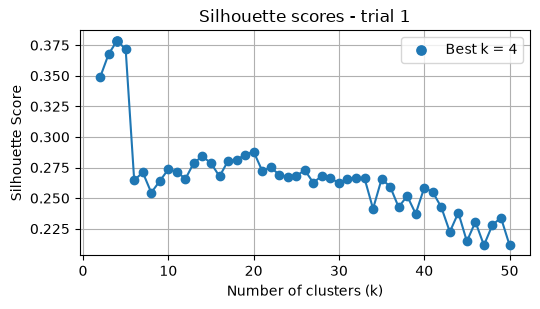

Chosen k in first run: 4


In [11]:
# plot silhouette scores vs k from first Monte Carlo run
plt.figure(figsize=(5.5,3.2))
plt.plot(first_run_k_values, first_run_sil_scores, marker='o')
plt.scatter(first_run_best_k,
            first_run_sil_scores[np.argmax(first_run_sil_scores)],
            s=45,
            label=f"Best k = {first_run_best_k}")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette scores - trial 1")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

print("Chosen k in first run:", first_run_best_k)

**Clustering interpretation.** All 50 searches selected k = 4. Mean Hamming distance was 0.676742 (sample SD 0.029603), or about 0.677 wrong labels per observation. Mean loss was 0.225581 and score was 0.774419, so 77.44% of individual output labels matched. These are full-dataset clustering measures, not held-out test scores.

# (3) ISLR 12.6.2

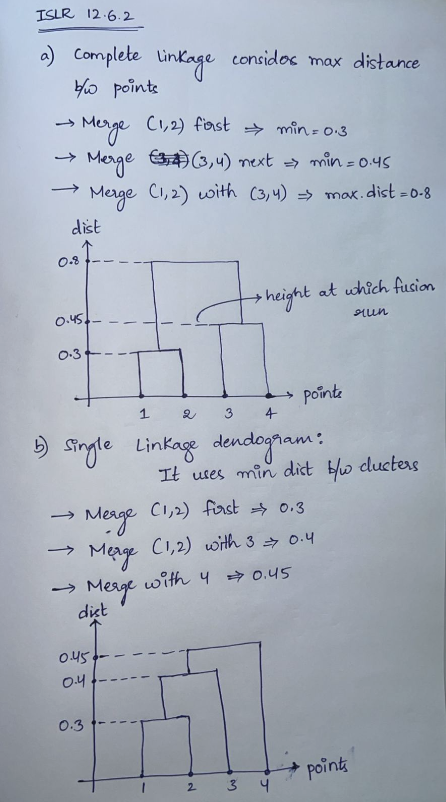

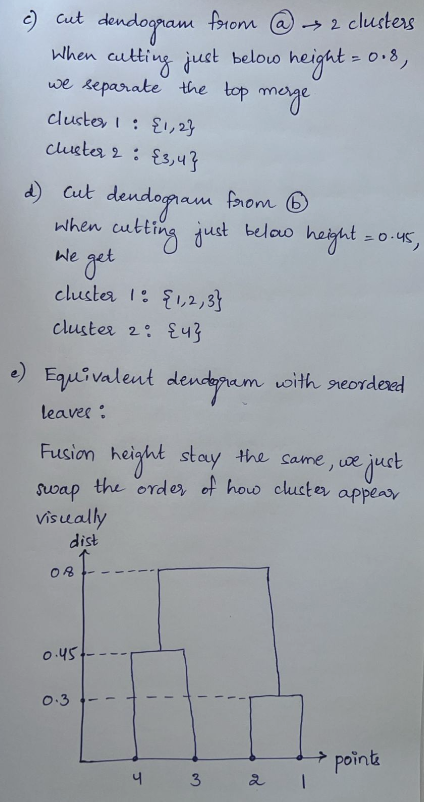

## References
- [Support vector machines](https://www.geeksforgeeks.org/machine-learning/support-vector-machine-algorithm/)
- [Silhouette score](https://medium.com/@hazallgultekin/what-is-silhouette-score-f428fb39bf9a)
- [Multiclass and multilabel classification](https://codefinity.com/blog/Multiclass-and-Multilabel-Classification)
- [Monte Carlo simulation](https://towardsdatascience.com/monte-carlo-simulations-b558f9246f2)
- [Hierarchical linkage](https://www.geeksforgeeks.org/machine-learning/ml-types-of-linkages-in-clustering/)

## AI assistance
ChatGPT (OpenAI) assisted with the following topics/prompts (condensed):

- Select k by silhouette and assign independent majority-label triplets.
- Define Hamming measures and evaluate 50 Monte Carlo clustering runs.
- Map clusters to true labels, review calculations, and visualize silhouette scores.